# 1.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from pathlib import Path

# 1.2 Load Modeling Dataset

In [2]:
data_path = Path("../data/processed/nba_modeling_dataset.csv")

game_level = pd.read_csv(
    data_path,
    dtype={"GAME_ID": str},
    parse_dates=["GAME_DATE"]
)

print("Dataset shape:", game_level.shape)
print("Unique games:", game_level["GAME_ID"].nunique())
print("Seasons:", game_level["SEASON"].nunique())

display(game_level.head())


Dataset shape: (13209, 29)
Unique games: 13209
Seasons: 11


,GAME_ID,SEASON,GAME_DATE,IS_NEUTRAL_SITE,HOME_TEAM_ID,HOME_TEAM_ABBREVIATION,HOME_REST_DAYS,HOME_IS_B2B,HOME_IS_3IN4,HOME_GAMES_LAST_7D,...,AWAY_GAMES_LAST_7D,AWAY_CONSECUTIVE_ROAD_GAMES,AWAY_TRAVEL_DISTANCE_KM,AWAY_WL,AWAY_PTS,HOME_WIN,POINT_DIFF,HOME_REST_DAYS_CAPPED,AWAY_REST_DAYS_CAPPED,IS_COVID_RESTART
0,0021400001,2014-15,2014-10-28,0,1610612740,NOP,NaN,0,0,0,...,0,1,NaN,L,84,1,17,NaN,NaN,0
1,0021400002,2014-15,2014-10-28,0,1610612759,SAS,NaN,0,0,0,...,0,1,NaN,L,100,1,1,NaN,NaN,0
2,0021400003,2014-15,2014-10-28,0,1610612747,LAL,NaN,0,0,0,...,0,1,NaN,W,108,0,-18,NaN,NaN,0
3,0021400004,2014-15,2014-10-29,0,1610612766,CHA,NaN,0,0,0,...,0,1,NaN,L,106,1,2,NaN,NaN,0
4,0021400005,2014-15,2014-10-29,0,1610612754,IND,NaN,0,0,0,...,0,1,NaN,L,91,1,12,NaN,NaN,0


# 1.3 Calculate Pre-game Team Strength

In [3]:
home_strength = game_level[
    ["GAME_ID", "GAME_DATE", "SEASON", "HOME_TEAM_ID", "HOME_WIN"]
].copy()

home_strength.columns = [
    "GAME_ID", "GAME_DATE", "SEASON", "TEAM_ID", "WIN"
]

away_strength = game_level[
    ["GAME_ID", "GAME_DATE", "SEASON", "AWAY_TEAM_ID", "HOME_WIN"]
].copy()

away_strength.columns = [
    "GAME_ID", "GAME_DATE", "SEASON", "TEAM_ID", "WIN"
]

away_strength["WIN"] = 1 - away_strength["WIN"]

team_strength = pd.concat(
    [home_strength, away_strength],
    ignore_index=True
).sort_values(
    ["TEAM_ID", "SEASON", "GAME_DATE", "GAME_ID"]
).reset_index(drop=True)

team_groups = team_strength.groupby(["TEAM_ID", "SEASON"])

team_strength["PRE_GAME_GAMES"] = team_groups.cumcount()

team_strength["PRE_GAME_WINS"] = (
    team_groups["WIN"].cumsum() - team_strength["WIN"]
)

k = 10

team_strength["PRE_GAME_WIN_PCT"] = (
    team_strength["PRE_GAME_WINS"] + 0.5 * k
) / (
    team_strength["PRE_GAME_GAMES"] + k
)

print("Team-game observations:", len(team_strength))

display(
    team_strength[
        [
            "SEASON",
            "TEAM_ID",
            "GAME_DATE",
            "WIN",
            "PRE_GAME_GAMES",
            "PRE_GAME_WINS",
            "PRE_GAME_WIN_PCT"
        ]
    ].head(15).round(3)
)


Team-game observations: 26418


/tmp/ipykernel_5312/2165902112.py:55: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(3)


,SEASON,TEAM_ID,GAME_DATE,WIN,PRE_GAME_GAMES,PRE_GAME_WINS,PRE_GAME_WIN_PCT
0,2014-15,1610612737,2014-10-29,0,0,0,0.500
1,2014-15,1610612737,2014-11-01,1,1,0,0.455
2,2014-15,1610612737,2014-11-05,0,2,1,0.500
3,2014-15,1610612737,2014-11-07,0,3,1,0.462
4,2014-15,1610612737,2014-11-08,1,4,1,0.429
5,2014-15,1610612737,2014-11-10,1,5,2,0.467
6,2014-15,1610612737,2014-11-12,1,6,3,0.500
7,2014-15,1610612737,2014-11-14,1,7,4,0.529
8,2014-15,1610612737,2014-11-15,0,8,5,0.556
9,2014-15,1610612737,2014-11-18,0,9,5,0.526


# 1.4 Merge Team Strength into Game Dataset

In [4]:
home_pre_game = team_strength[
    ["GAME_ID", "TEAM_ID", "PRE_GAME_WIN_PCT"]
].rename(
    columns={
        "TEAM_ID": "HOME_TEAM_ID",
        "PRE_GAME_WIN_PCT": "HOME_STRENGTH"
    }
)

away_pre_game = team_strength[
    ["GAME_ID", "TEAM_ID", "PRE_GAME_WIN_PCT"]
].rename(
    columns={
        "TEAM_ID": "AWAY_TEAM_ID",
        "PRE_GAME_WIN_PCT": "AWAY_STRENGTH"
    }
)

game_level = game_level.merge(
    home_pre_game,
    on=["GAME_ID", "HOME_TEAM_ID"],
    how="left",
    validate="one_to_one"
)

game_level = game_level.merge(
    away_pre_game,
    on=["GAME_ID", "AWAY_TEAM_ID"],
    how="left",
    validate="one_to_one"
)

game_level["STRENGTH_DIFF"] = (
    game_level["HOME_STRENGTH"] - game_level["AWAY_STRENGTH"]
)

print("Total games:", len(game_level))
print("Missing home strength:", game_level["HOME_STRENGTH"].isna().sum())
print("Missing away strength:", game_level["AWAY_STRENGTH"].isna().sum())

display(
    game_level[
        [
            "SEASON",
            "GAME_DATE",
            "HOME_TEAM_ABBREVIATION",
            "AWAY_TEAM_ABBREVIATION",
            "HOME_STRENGTH",
            "AWAY_STRENGTH",
            "STRENGTH_DIFF"
        ]
    ].head(10).round(3)
)


Total games: 13209
Missing home strength: 0
Missing away strength: 0


/tmp/ipykernel_5312/3531548890.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(3)


,SEASON,GAME_DATE,HOME_TEAM_ABBREVIATION,AWAY_TEAM_ABBREVIATION,HOME_STRENGTH,AWAY_STRENGTH,STRENGTH_DIFF
0,2014-15,2014-10-28,NOP,ORL,0.5,0.5,0.0
1,2014-15,2014-10-28,SAS,DAL,0.5,0.5,0.0
2,2014-15,2014-10-28,LAL,HOU,0.5,0.5,0.0
3,2014-15,2014-10-29,CHA,MIL,0.5,0.5,0.0
4,2014-15,2014-10-29,IND,PHI,0.5,0.5,0.0
5,2014-15,2014-10-29,BOS,BKN,0.5,0.5,0.0
6,2014-15,2014-10-29,MIA,WAS,0.5,0.5,0.0
7,2014-15,2014-10-29,TOR,ATL,0.5,0.5,0.0
8,2014-15,2014-10-29,MEM,MIN,0.5,0.5,0.0
9,2014-15,2014-10-29,NYK,CHI,0.5,0.5,0.0


# 2.1 H1 Regression Analysis of Back-to-Back Effects

In [5]:
h1_model = smf.ols(
    "POINT_DIFF ~ HOME_IS_B2B + AWAY_IS_B2B + STRENGTH_DIFF + C(SEASON)",
    data=game_level
).fit(cov_type="HC3")

print(h1_model.summary())


                            OLS Regression Results                            
Dep. Variable:             POINT_DIFF   R-squared:                       0.144
Model:                            OLS   Adj. R-squared:                  0.143
Method:                 Least Squares   F-statistic:                     179.9
Date:                Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                        08:19:32   Log-Likelihood:                -52968.
No. Observations:               13209   AIC:                         1.060e+05
Df Residuals:                   13195   BIC:                         1.061e+05
Df Model:                          13                                         
Covariance Type:                  HC3                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                1.9945 

In [6]:
h1_variables = [
    "HOME_IS_B2B",
    "AWAY_IS_B2B",
    "STRENGTH_DIFF"
]

h1_results = pd.DataFrame({
    "Coefficient": h1_model.params[h1_variables],
    "Std_Error": h1_model.bse[h1_variables],
    "P_Value": h1_model.pvalues[h1_variables],
    "CI_Lower": h1_model.conf_int().loc[h1_variables, 0],
    "CI_Upper": h1_model.conf_int().loc[h1_variables, 1]
})

display(h1_results.round(4))


,Coefficient,Std_Error,P_Value,CI_Lower,CI_Upper
HOME_IS_B2B,-1.9114,0.3394,0.0,-2.5767,-1.2462
AWAY_IS_B2B,2.2030,0.2779,0.0,1.6584,2.7477
STRENGTH_DIFF,31.3635,0.6635,0.0,30.0630,32.6640


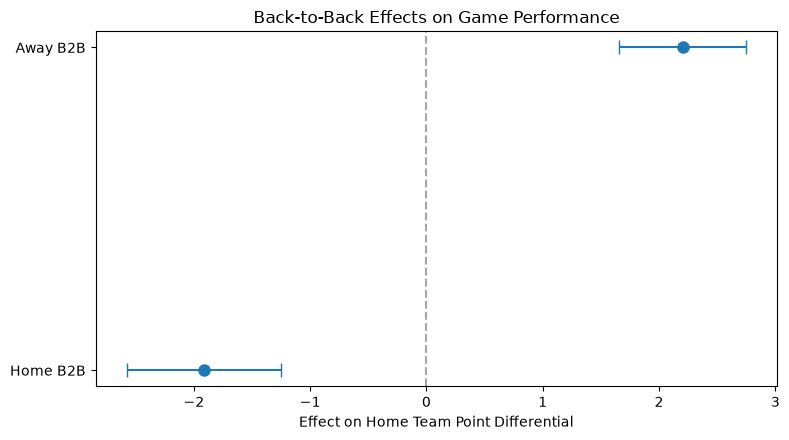

In [7]:
h1_plot = h1_results.loc[
    ["HOME_IS_B2B", "AWAY_IS_B2B"]
].copy()

h1_plot.index = ["Home B2B", "Away B2B"]

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.errorbar(
    h1_plot["Coefficient"],
    h1_plot.index,
    xerr=[
        h1_plot["Coefficient"] - h1_plot["CI_Lower"],
        h1_plot["CI_Upper"] - h1_plot["Coefficient"]
    ],
    fmt="o",
    capsize=5,
    markersize=8
)

ax.axvline(0, linestyle="--", color="gray", alpha=0.7)

ax.set_xlabel("Effect on Home Team Point Differential")
ax.set_title("Back-to-Back Effects on Game Performance")

plt.tight_layout()

output_dir = Path("../outputs/figures")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "h1_b2b_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3.1 H2 Regression with Team Strength Controls

In [8]:
h2_data = game_level.loc[
    game_level["AWAY_TRAVEL_DISTANCE_KM"].notna()
].copy()

h2_data["AWAY_POINT_DIFF"] = -h2_data["POINT_DIFF"]

h2_data["AWAY_TRAVEL_1000KM"] = (
    h2_data["AWAY_TRAVEL_DISTANCE_KM"] / 1000
)

h2_model_adjusted = smf.ols(
    "AWAY_POINT_DIFF ~ AWAY_IS_B2B * AWAY_TRAVEL_1000KM + STRENGTH_DIFF + C(SEASON)",
    data=h2_data
).fit(cov_type="HC3")

h2_variables = [
    "AWAY_IS_B2B",
    "AWAY_TRAVEL_1000KM",
    "AWAY_IS_B2B:AWAY_TRAVEL_1000KM",
    "STRENGTH_DIFF"
]

h2_results = pd.DataFrame({
    "Coefficient": h2_model_adjusted.params[h2_variables],
    "Std_Error": h2_model_adjusted.bse[h2_variables],
    "P_Value": h2_model_adjusted.pvalues[h2_variables],
    "CI_Lower": h2_model_adjusted.conf_int().loc[h2_variables, 0],
    "CI_Upper": h2_model_adjusted.conf_int().loc[h2_variables, 1]
})

print("Observations:", int(h2_model_adjusted.nobs))
print("R-squared:", round(h2_model_adjusted.rsquared, 4))

display(h2_results.round(4))


Observations: 13046
R-squared: 0.1438


,Coefficient,Std_Error,P_Value,CI_Lower,CI_Upper
AWAY_IS_B2B,-1.3541,0.5335,0.0112,-2.3998,-0.3084
AWAY_TRAVEL_1000KM,0.0594,0.1607,0.7116,-0.2555,0.3744
AWAY_IS_B2B:AWAY_TRAVEL_1000KM,-0.7631,0.5381,0.1562,-1.8178,0.2917
STRENGTH_DIFF,-31.3566,0.6640,0.0000,-32.6580,-30.0552


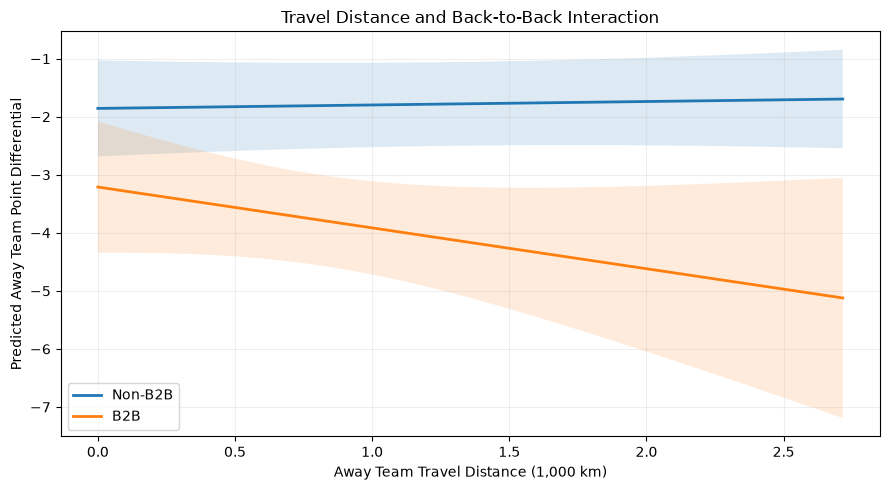

In [9]:
travel_range = np.linspace(
    0,
    h2_data["AWAY_TRAVEL_1000KM"].quantile(0.95),
    100
)

prediction_data = pd.DataFrame({
    "AWAY_TRAVEL_1000KM": np.tile(travel_range, 2),
    "AWAY_IS_B2B": np.repeat([0, 1], len(travel_range)),
    "STRENGTH_DIFF": 0,
    "SEASON": game_level["SEASON"].mode()[0]
})

predictions = h2_model_adjusted.get_prediction(
    prediction_data
).summary_frame(alpha=0.05)

prediction_data["PREDICTED_POINT_DIFF"] = predictions["mean"].to_numpy()
prediction_data["CI_LOWER"] = predictions["mean_ci_lower"].to_numpy()
prediction_data["CI_UPPER"] = predictions["mean_ci_upper"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5))

for b2b, label in [(0, "Non-B2B"), (1, "B2B")]:
    subset = prediction_data[
        prediction_data["AWAY_IS_B2B"] == b2b
    ]

    ax.plot(
        subset["AWAY_TRAVEL_1000KM"],
        subset["PREDICTED_POINT_DIFF"],
        label=label,
        linewidth=2
    )

    ax.fill_between(
        subset["AWAY_TRAVEL_1000KM"],
        subset["CI_LOWER"],
        subset["CI_UPPER"],
        alpha=0.15
    )

ax.set_xlabel("Away Team Travel Distance (1,000 km)")
ax.set_ylabel("Predicted Away Team Point Differential")
ax.set_title("Travel Distance and Back-to-Back Interaction")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    output_dir / "h2_travel_b2b_interaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 4.1 H3 Regression with Team Strength Controls

In [10]:
h3_data = pd.concat([
    game_level.assign(
        POINT_DIFFERENTIAL=game_level["POINT_DIFF"],
        GAMES_LAST_7D=game_level["HOME_GAMES_LAST_7D"],
        IS_HOME=1,
        TEAM_STRENGTH_DIFF=game_level["STRENGTH_DIFF"]
    ),
    game_level.assign(
        POINT_DIFFERENTIAL=-game_level["POINT_DIFF"],
        GAMES_LAST_7D=game_level["AWAY_GAMES_LAST_7D"],
        IS_HOME=0,
        TEAM_STRENGTH_DIFF=-game_level["STRENGTH_DIFF"]
    )
], ignore_index=True)

h3_data["DENSITY_GROUP"] = (
    h3_data["GAMES_LAST_7D"].clip(upper=4).astype(int)
)

h3_model_adjusted = smf.ols(
    "POINT_DIFFERENTIAL ~ C(DENSITY_GROUP, Treatment(reference=2)) + IS_HOME + TEAM_STRENGTH_DIFF + C(SEASON)",
    data=h3_data
).fit(cov_type="HC3")

h3_terms = [
    term for term in h3_model_adjusted.params.index
    if "DENSITY_GROUP" in term
]

h3_results = pd.DataFrame({
    "Coefficient": h3_model_adjusted.params[h3_terms],
    "P_Value": h3_model_adjusted.pvalues[h3_terms],
    "CI_Lower": h3_model_adjusted.conf_int().loc[h3_terms, 0],
    "CI_Upper": h3_model_adjusted.conf_int().loc[h3_terms, 1]
})

print("Observations:", int(h3_model_adjusted.nobs))
print("R-squared:", round(h3_model_adjusted.rsquared, 4))

display(h3_results.round(4))


Observations: 26418
R-squared: 0.1575


,Coefficient,P_Value,CI_Lower,CI_Upper
"C(DENSITY_GROUP, Treatment(reference=2))[T.0]",-0.7480,0.2084,-1.9134,0.4173
"C(DENSITY_GROUP, Treatment(reference=2))[T.1]",-0.3501,0.5353,-1.4572,0.7569
"C(DENSITY_GROUP, Treatment(reference=2))[T.3]",-0.6636,0.0151,-1.1990,-0.1282
"C(DENSITY_GROUP, Treatment(reference=2))[T.4]",-1.2570,0.0000,-1.8255,-0.6885


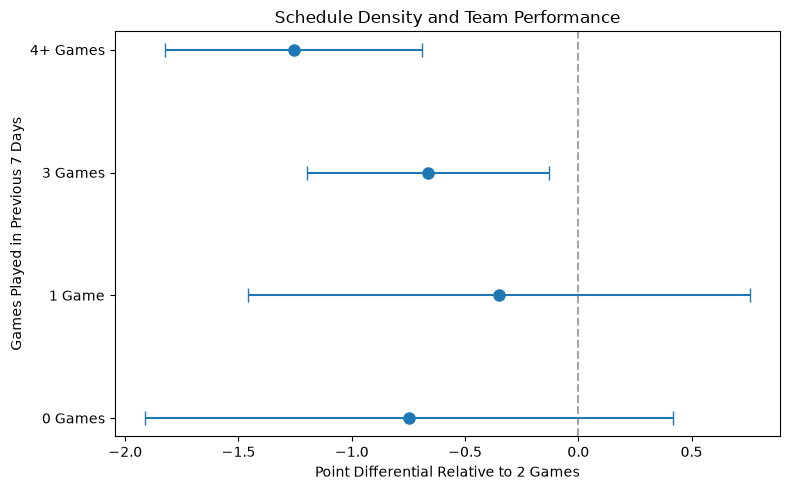

In [11]:
h3_plot = h3_results.copy()

h3_plot.index = [
    "0 Games",
    "1 Game",
    "3 Games",
    "4+ Games"
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    h3_plot["Coefficient"],
    h3_plot.index,
    xerr=[
        h3_plot["Coefficient"] - h3_plot["CI_Lower"],
        h3_plot["CI_Upper"] - h3_plot["Coefficient"]
    ],
    fmt="o",
    capsize=5,
    markersize=8
)

ax.axvline(0, linestyle="--", color="gray", alpha=0.7)

ax.set_xlabel("Point Differential Relative to 2 Games")
ax.set_ylabel("Games Played in Previous 7 Days")
ax.set_title("Schedule Density and Team Performance")

plt.tight_layout()

plt.savefig(
    output_dir / "h3_schedule_density_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 5.1 Consolidated Regression Results

In [12]:
regression_summary = pd.concat([
    h1_results.assign(Model="H1"),
    h2_results.assign(Model="H2"),
    h3_results.assign(Model="H3")
])

regression_summary = regression_summary.reset_index().rename(
    columns={"index": "Variable"}
)

regression_summary = regression_summary[
    ["Model", "Variable", "Coefficient", "P_Value", "CI_Lower", "CI_Upper"]
]

output_dir_tables = Path("../outputs/tables")
output_dir_tables.mkdir(parents=True, exist_ok=True)

regression_summary.to_csv(
    output_dir_tables / "regression_summary.csv",
    index=False
)

display(regression_summary.round(4))


,Model,Variable,Coefficient,P_Value,CI_Lower,CI_Upper
0,H1,HOME_IS_B2B,-1.9114,0.0000,-2.5767,-1.2462
1,H1,AWAY_IS_B2B,2.2030,0.0000,1.6584,2.7477
2,H1,STRENGTH_DIFF,31.3635,0.0000,30.0630,32.6640
3,H2,AWAY_IS_B2B,-1.3541,0.0112,-2.3998,-0.3084
4,H2,AWAY_TRAVEL_1000KM,0.0594,0.7116,-0.2555,0.3744
5,H2,AWAY_IS_B2B:AWAY_TRAVEL_1000KM,-0.7631,0.1562,-1.8178,0.2917
6,H2,STRENGTH_DIFF,-31.3566,0.0000,-32.6580,-30.0552
7,H3,"C(DENSITY_GROUP, Treatment(reference=2))[T.0]",-0.7480,0.2084,-1.9134,0.4173
8,H3,"C(DENSITY_GROUP, Treatment(reference=2))[T.1]",-0.3501,0.5353,-1.4572,0.7569
9,H3,"C(DENSITY_GROUP, Treatment(reference=2))[T.3]",-0.6636,0.0151,-1.1990,-0.1282


# 6.1 H4 Back-to-Back Schedule Burden Distribution

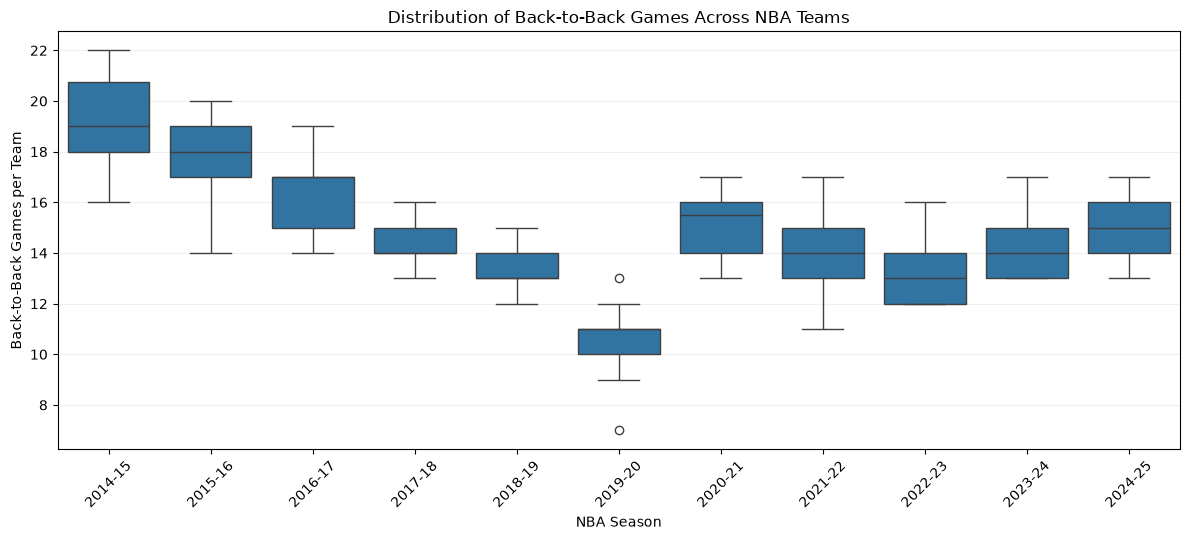

In [13]:
h4_home = game_level[
    ["SEASON", "HOME_TEAM_ID", "HOME_IS_B2B"]
].rename(
    columns={
        "HOME_TEAM_ID": "TEAM_ID",
        "HOME_IS_B2B": "IS_B2B"
    }
)

h4_away = game_level[
    ["SEASON", "AWAY_TEAM_ID", "AWAY_IS_B2B"]
].rename(
    columns={
        "AWAY_TEAM_ID": "TEAM_ID",
        "AWAY_IS_B2B": "IS_B2B"
    }
)

h4_team_games = pd.concat(
    [h4_home, h4_away],
    ignore_index=True
)

h4_team_season = (
    h4_team_games
    .groupby(["SEASON", "TEAM_ID"], as_index=False)
    .agg(B2B_GAMES=("IS_B2B", "sum"))
)

season_order = sorted(h4_team_season["SEASON"].unique())

fig, ax = plt.subplots(figsize=(12, 5.5))

sns.boxplot(
    data=h4_team_season,
    x="SEASON",
    y="B2B_GAMES",
    order=season_order,
    ax=ax
)

ax.set_title("Distribution of Back-to-Back Games Across NBA Teams")
ax.set_xlabel("NBA Season")
ax.set_ylabel("Back-to-Back Games per Team")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    output_dir / "h4_b2b_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 6.2 H4 Team Travel Distance Comparison

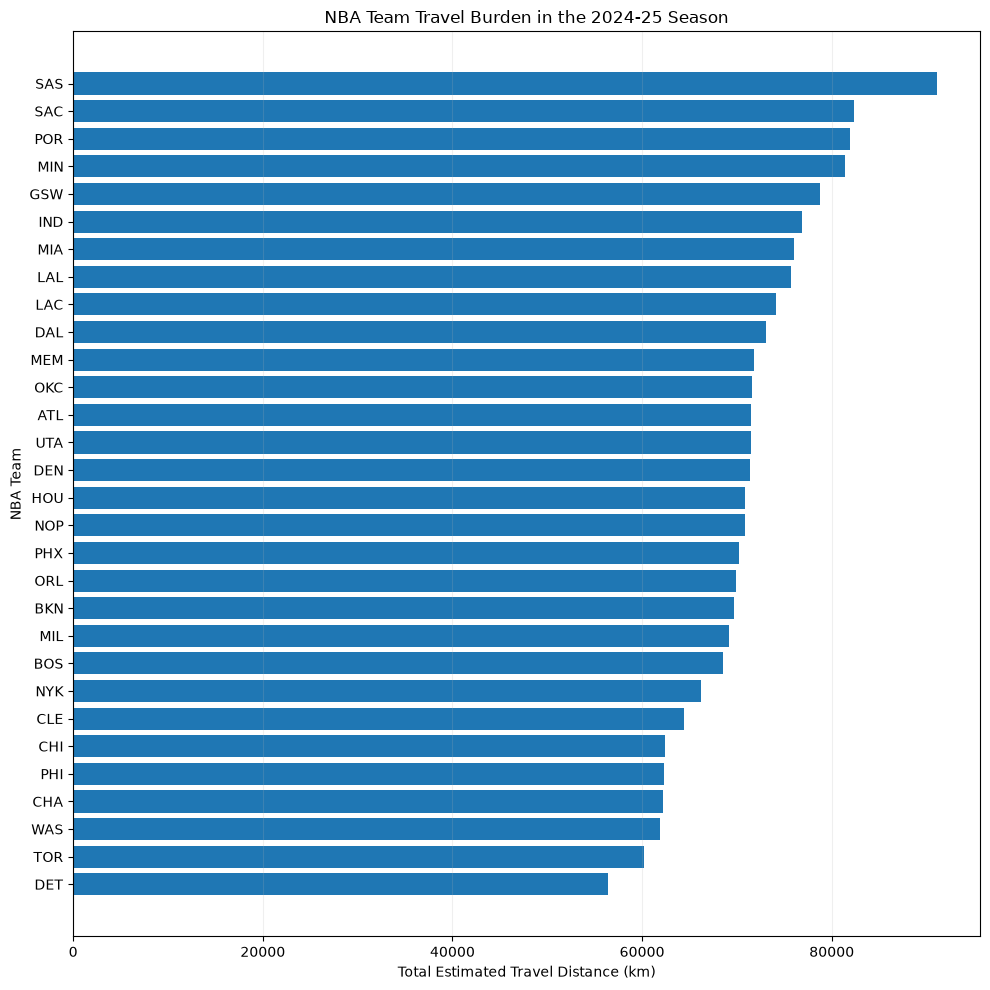

,TEAM,TOTAL_TRAVEL_KM
26,SAS,91082.4
25,SAC,82371.5
24,POR,81877.8
17,MIN,81368.1
9,GSW,78723.4


In [14]:
h4_home_travel = game_level[
    ["SEASON", "HOME_TEAM_ABBREVIATION", "HOME_TRAVEL_DISTANCE_KM"]
].rename(
    columns={
        "HOME_TEAM_ABBREVIATION": "TEAM",
        "HOME_TRAVEL_DISTANCE_KM": "TRAVEL_DISTANCE_KM"
    }
)

h4_away_travel = game_level[
    ["SEASON", "AWAY_TEAM_ABBREVIATION", "AWAY_TRAVEL_DISTANCE_KM"]
].rename(
    columns={
        "AWAY_TEAM_ABBREVIATION": "TEAM",
        "AWAY_TRAVEL_DISTANCE_KM": "TRAVEL_DISTANCE_KM"
    }
)

h4_travel = pd.concat(
    [h4_home_travel, h4_away_travel],
    ignore_index=True
)

h4_travel_2025 = (
    h4_travel[h4_travel["SEASON"] == "2024-25"]
    .groupby("TEAM", as_index=False)
    .agg(TOTAL_TRAVEL_KM=("TRAVEL_DISTANCE_KM", "sum"))
    .sort_values("TOTAL_TRAVEL_KM", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 10))

ax.barh(
    h4_travel_2025["TEAM"],
    h4_travel_2025["TOTAL_TRAVEL_KM"]
)

ax.set_xlabel("Total Estimated Travel Distance (km)")
ax.set_ylabel("NBA Team")
ax.set_title("NBA Team Travel Burden in the 2024-25 Season")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    output_dir / "h4_team_travel_2024_25.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    h4_travel_2025.sort_values(
        "TOTAL_TRAVEL_KM", ascending=False
    ).head(5).round(1)
)


# 6.3 H4 Schedule Fairness Summary

In [15]:
h4_travel_season = (
    h4_travel
    .groupby(["SEASON", "TEAM"], as_index=False)
    .agg(TOTAL_TRAVEL_KM=("TRAVEL_DISTANCE_KM", "sum"))
)

h4_b2b_summary = (
    h4_team_season
    .groupby("SEASON")
    .agg(
        B2B_MEAN=("B2B_GAMES", "mean"),
        B2B_MIN=("B2B_GAMES", "min"),
        B2B_MAX=("B2B_GAMES", "max"),
        B2B_STD=("B2B_GAMES", "std")
    )
)

h4_travel_summary = (
    h4_travel_season
    .groupby("SEASON")
    .agg(
        TRAVEL_MEAN_KM=("TOTAL_TRAVEL_KM", "mean"),
        TRAVEL_MIN_KM=("TOTAL_TRAVEL_KM", "min"),
        TRAVEL_MAX_KM=("TOTAL_TRAVEL_KM", "max"),
        TRAVEL_STD_KM=("TOTAL_TRAVEL_KM", "std")
    )
)

h4_summary = h4_b2b_summary.join(h4_travel_summary)

h4_summary["B2B_RANGE"] = (
    h4_summary["B2B_MAX"] - h4_summary["B2B_MIN"]
)

h4_summary["TRAVEL_RANGE_KM"] = (
    h4_summary["TRAVEL_MAX_KM"] - h4_summary["TRAVEL_MIN_KM"]
)

h4_summary.to_csv(
    output_dir_tables / "h4_schedule_fairness_summary.csv"
)

display(h4_summary.round(2))


,B2B_MEAN,B2B_MIN,B2B_MAX,B2B_STD,TRAVEL_MEAN_KM,TRAVEL_MIN_KM,TRAVEL_MAX_KM,TRAVEL_STD_KM,B2B_RANGE,TRAVEL_RANGE_KM
SEASON,,,,,,,,,,
2014-15,19.33,16,22,1.56,73412.22,56474.53,100186.50,9975.59,6,43711.97
2015-16,17.80,14,20,1.77,71789.57,56284.15,91683.82,8939.05,6,35399.67
2016-17,16.37,14,19,1.33,74965.29,59831.07,92870.64,9436.69,5,33039.56
2017-18,14.43,13,16,0.82,73730.89,60721.56,87273.23,8241.82,3,26551.67
2018-19,13.27,12,15,0.94,72687.00,56988.50,87277.16,7976.19,3,30288.65
2019-20,10.50,7,13,1.28,60418.41,39277.52,76210.70,8239.42,6,36933.18
2020-21,15.23,13,17,1.41,59832.64,47474.95,69926.22,5963.63,4,22451.28
2021-22,14.10,11,17,1.42,69017.21,56622.50,82152.92,7551.77,6,25530.42
2022-23,13.37,12,16,1.19,66554.37,53780.27,79193.93,7355.56,4,25413.66


## Schedule Fatigue Index

In [16]:
home_sfi = pd.DataFrame({
    "GAME_ID": game_level["GAME_ID"],
    "SEASON": game_level["SEASON"],
    "TEAM_ID": game_level["HOME_TEAM_ID"],
    "POINT_DIFFERENTIAL": game_level["POINT_DIFF"],
    "IS_B2B": game_level["HOME_IS_B2B"],
    "GAMES_LAST_7D": game_level["HOME_GAMES_LAST_7D"],
    "TRAVEL_DISTANCE_KM": game_level["HOME_TRAVEL_DISTANCE_KM"],
    "STRENGTH_DIFF": game_level["STRENGTH_DIFF"],
    "IS_HOME": 1
})

away_sfi = pd.DataFrame({
    "GAME_ID": game_level["GAME_ID"],
    "SEASON": game_level["SEASON"],
    "TEAM_ID": game_level["AWAY_TEAM_ID"],
    "POINT_DIFFERENTIAL": -game_level["POINT_DIFF"],
    "IS_B2B": game_level["AWAY_IS_B2B"],
    "GAMES_LAST_7D": game_level["AWAY_GAMES_LAST_7D"],
    "TRAVEL_DISTANCE_KM": game_level["AWAY_TRAVEL_DISTANCE_KM"],
    "STRENGTH_DIFF": -game_level["STRENGTH_DIFF"],
    "IS_HOME": 0
})

sfi_data = pd.concat([home_sfi, away_sfi], ignore_index=True)

print("Team-game observations:", len(sfi_data))
print("Unique games:", sfi_data["GAME_ID"].nunique())
print("Missing values:")
print(sfi_data.isna().sum())


Team-game observations: 26418
Unique games: 13209
Missing values:
GAME_ID                 0
SEASON                  0
TEAM_ID                 0
POINT_DIFFERENTIAL      0
IS_B2B                  0
GAMES_LAST_7D           0
TRAVEL_DISTANCE_KM    330
STRENGTH_DIFF           0
IS_HOME                 0
dtype: int64


In [17]:
train_seasons = [
    "2014-15", "2015-16", "2016-17", "2017-18",
    "2018-19", "2019-20", "2020-21", "2021-22"
]

test_seasons = [
    "2022-23", "2023-24", "2024-25"
]

sfi_train = sfi_data[sfi_data["SEASON"].isin(train_seasons)].copy()
sfi_test = sfi_data[sfi_data["SEASON"].isin(test_seasons)].copy()

print("Training observations:", len(sfi_train))
print("Testing observations:", len(sfi_test))
print("Total observations:", len(sfi_train) + len(sfi_test))
print("Unassigned observations:", len(sfi_data) - len(sfi_train) - len(sfi_test))
print("Training seasons:", sorted(sfi_train["SEASON"].unique()))
print("Testing seasons:", sorted(sfi_test["SEASON"].unique()))


Training observations: 19038
Testing observations: 7380
Total observations: 26418
Unassigned observations: 0
Training seasons: ['2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22']
Testing seasons: ['2022-23', '2023-24', '2024-25']


In [18]:
sfi_features = [
    "IS_B2B",
    "GAMES_LAST_7D",
    "TRAVEL_DISTANCE_KM"
]

required_columns = sfi_features + [
    "POINT_DIFFERENTIAL",
    "STRENGTH_DIFF",
    "IS_HOME",
    "GAME_ID",
    "SEASON"
]

sfi_train = sfi_train.dropna(subset=required_columns).copy()
sfi_test = sfi_test.dropna(subset=required_columns).copy()

feature_means = sfi_train[sfi_features].mean()
feature_stds = sfi_train[sfi_features].std()

assert (feature_stds > 0).all()

for feature in sfi_features:
    sfi_train[f"{feature}_Z"] = (
        sfi_train[feature] - feature_means[feature]
    ) / feature_stds[feature]

    sfi_test[f"{feature}_Z"] = (
        sfi_test[feature] - feature_means[feature]
    ) / feature_stds[feature]

print("Training observations:", len(sfi_train))
print("Testing observations:", len(sfi_test))
print("\nTraining feature statistics:")
print(pd.DataFrame({
    "Mean": feature_means,
    "Standard Deviation": feature_stds
}))

print("\nStandardized training feature means:")
print(sfi_train[[f"{x}_Z" for x in sfi_features]].mean().round(6))

print("\nMissing standardized values:")
print(sfi_train[[f"{x}_Z" for x in sfi_features]].isna().sum())


Training observations: 18798
Testing observations: 7290

Training feature statistics:
                          Mean  Standard Deviation
IS_B2B                0.193159            0.394787
GAMES_LAST_7D         3.108948            0.813283
TRAVEL_DISTANCE_KM  887.094229          892.362606

Standardized training feature means:
IS_B2B_Z                0.0
GAMES_LAST_7D_Z        -0.0
TRAVEL_DISTANCE_KM_Z   -0.0
dtype: float64

Missing standardized values:
IS_B2B_Z                0
GAMES_LAST_7D_Z         0
TRAVEL_DISTANCE_KM_Z    0
dtype: int64


In [19]:
sfi_model = smf.ols(
    formula=(
        "POINT_DIFFERENTIAL ~ "
        "IS_B2B_Z + "
        "GAMES_LAST_7D_Z + "
        "TRAVEL_DISTANCE_KM_Z + "
        "STRENGTH_DIFF + "
        "IS_HOME + "
        "C(SEASON)"
    ),
    data=sfi_train
).fit(
    cov_type="cluster",
    cov_kwds={"groups": sfi_train["GAME_ID"]}
)

sfi_coefficients = [
    "IS_B2B_Z",
    "GAMES_LAST_7D_Z",
    "TRAVEL_DISTANCE_KM_Z"
]

sfi_results = pd.DataFrame({
    "Coefficient": sfi_model.params[sfi_coefficients],
    "Standard Error": sfi_model.bse[sfi_coefficients],
    "P-value": sfi_model.pvalues[sfi_coefficients],
    "CI Lower": sfi_model.conf_int().loc[sfi_coefficients, 0],
    "CI Upper": sfi_model.conf_int().loc[sfi_coefficients, 1]
})

print("Training observations:", int(sfi_model.nobs))
print("R-squared:", round(sfi_model.rsquared, 4))
print("\nSchedule Fatigue Regression Results:")
print(sfi_results.round(4))


Training observations: 18798
R-squared: 0.1562

Schedule Fatigue Regression Results:
                      Coefficient  Standard Error  P-value  CI Lower  CI Upper
IS_B2B_Z                  -0.6279          0.0927   0.0000   -0.8097   -0.4462
GAMES_LAST_7D_Z           -0.1710          0.0717   0.0170   -0.3115   -0.0305
TRAVEL_DISTANCE_KM_Z      -0.0356          0.0987   0.7185   -0.2289    0.1578


In [20]:
sfi_feature_correlations = sfi_train[
    [
        "IS_B2B_Z",
        "GAMES_LAST_7D_Z",
        "TRAVEL_DISTANCE_KM_Z"
    ]
].corr()

print("Schedule Fatigue Feature Correlations:")
print(sfi_feature_correlations.round(4))


Schedule Fatigue Feature Correlations:
                      IS_B2B_Z  GAMES_LAST_7D_Z  TRAVEL_DISTANCE_KM_Z
IS_B2B_Z                1.0000           0.1997               -0.0862
GAMES_LAST_7D_Z         0.1997           1.0000               -0.0586
TRAVEL_DISTANCE_KM_Z   -0.0862          -0.0586                1.0000


In [21]:
sfi_weights = -sfi_model.params[sfi_coefficients]

sfi_weights = sfi_weights / sfi_weights.sum()

for dataset in [sfi_train, sfi_test]:
    dataset["SFI_RAW"] = (
        sfi_weights["IS_B2B_Z"] * dataset["IS_B2B_Z"]
        + sfi_weights["GAMES_LAST_7D_Z"] * dataset["GAMES_LAST_7D_Z"]
        + sfi_weights["TRAVEL_DISTANCE_KM_Z"] * dataset["TRAVEL_DISTANCE_KM_Z"]
    )

sfi_min = sfi_train["SFI_RAW"].min()
sfi_max = sfi_train["SFI_RAW"].max()

for dataset in [sfi_train, sfi_test]:
    dataset["SFI"] = (
        100 * (dataset["SFI_RAW"] - sfi_min)
        / (sfi_max - sfi_min)
    )

print("SFI Weights:")
print((sfi_weights * 100).round(2))

print("\nTraining SFI Summary:")
print(sfi_train["SFI"].describe().round(2))

print("\nTesting SFI Summary:")
print(sfi_test["SFI"].describe().round(2))


SFI Weights:
IS_B2B_Z                75.25
GAMES_LAST_7D_Z         20.49
TRAVEL_DISTANCE_KM_Z     4.26
dtype: float64

Training SFI Summary:
count    18798.00
mean        37.71
std         25.76
min          0.00
25%         23.88
50%         26.34
75%         33.97
max        100.00
Name: SFI, dtype: float64

Testing SFI Summary:
count    7290.00
mean       36.34
std        24.69
min         0.00
25%        23.88
50%        26.10
75%        33.45
max       100.00
Name: SFI, dtype: float64
